# RetailPulse — Advanced Inactivity Models

**Purpose:** compare XGBoost and CatBoost against the existing Logistic Regression and Gradient Boosting baselines for the same 90-day customer-inactivity task.

**Protocol retained from Notebook 04**
- Six calendar months of transaction history to construct customer features.
- Predict whether a customer makes **no purchase in the following three calendar months**.
- Target: `Inactive = 1` means no future purchase; `Inactive = 0` means at least one future purchase.
- Chronological split: training snapshots through October 2010, validation snapshots February–April 2011, and the August 2011 snapshot as the previously designated test period.
- The test set is **not used for model selection** in this notebook. Since it has already been inspected in earlier experiments, treat it as a previously seen holdout rather than a pristine final test.

This notebook rebuilds the modelling table from the cleaned transaction file so it can run independently of Notebook 04. It does not hardcode sample sizes or expected scores; all counts and metrics are calculated from the data at runtime.

**Important:** this is an advanced-model comparison on the existing temporal split, not a complete nested-CV or publication-grade retuning exercise. Do not describe validation results as final test performance.


In [1]:
# 1. Imports and project paths

from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay, brier_score_loss
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer

RANDOM_STATE = 42

# Supports running from either the project root or the notebooks directory.
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "inactivity"
FIGURE_DIR = PROJECT_ROOT / "docs" / "inactivity" / "figures"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "cleaned_transactions.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Run this notebook from the RetailPulse "
        "project or its notebooks folder, and ensure preprocessing has created "
        "data/processed/cleaned_transactions.csv."
    )

print("Project root:", PROJECT_ROOT)
print("Input file:", DATA_PATH)


Project root: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse
Input file: c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\data\processed\cleaned_transactions.csv


In [2]:
# 2. Load cleaned transactions

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["InvoiceDate"],
    dtype={"Invoice": "string", "StockCode": "string"},
    low_memory=False
)

required_columns = {
    "Customer ID", "Invoice", "InvoiceDate", "StockCode",
    "Quantity", "TransactionValue"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Cleaned transaction data is missing columns: {sorted(missing_columns)}")

df = df.loc[df["Customer ID"].notna()].copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df = df.sort_values("InvoiceDate").reset_index(drop=True)

print("Transaction rows:", len(df))
print("Identified customers:", df["Customer ID"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())


Transaction rows: 779425
Identified customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


## 3. Rebuild the customer-snapshot modelling data

The following cells reproduce the feature and label construction used in Notebook 04. Features are calculated only from the six-month observation window. The target is calculated only from the subsequent three-month prediction window.


In [3]:
# 3.1 Define the same calendar-month observation and prediction windows

OBSERVATION_MONTHS = 6
PREDICTION_MONTHS = 3

snapshot_dates = pd.date_range(
    start="2010-05-31",
    end="2011-08-31",
    freq="ME"
)

window_records = []
for snapshot in snapshot_dates:
    snapshot_period = snapshot.to_period("M")
    window_records.append({
        "Observation Start": (snapshot_period - (OBSERVATION_MONTHS - 1)).start_time,
        "Observation End": snapshot_period.end_time,
        "Prediction Start": (snapshot_period + 1).start_time,
        "Prediction End": (snapshot_period + PREDICTION_MONTHS).end_time
    })

snapshot_windows_df = pd.DataFrame(window_records)

data_end = df["InvoiceDate"].max()
if snapshot_windows_df["Prediction End"].max() > data_end:
    raise ValueError(
        "The cleaned transaction data does not cover every defined prediction window. "
        "Check the dataset endpoint and snapshot schedule before modelling."
    )

display(snapshot_windows_df)


,Observation Start,Observation End,Prediction Start,Prediction End
0,2009-12-01,2010-05-31 23:59:59.999999999,2010-06-01,2010-08-31 23:59:59.999999999
1,2010-01-01,2010-06-30 23:59:59.999999999,2010-07-01,2010-09-30 23:59:59.999999999
2,2010-02-01,2010-07-31 23:59:59.999999999,2010-08-01,2010-10-31 23:59:59.999999999
3,2010-03-01,2010-08-31 23:59:59.999999999,2010-09-01,2010-11-30 23:59:59.999999999
4,2010-04-01,2010-09-30 23:59:59.999999999,2010-10-01,2010-12-31 23:59:59.999999999
5,2010-05-01,2010-10-31 23:59:59.999999999,2010-11-01,2011-01-31 23:59:59.999999999
6,2010-06-01,2010-11-30 23:59:59.999999999,2010-12-01,2011-02-28 23:59:59.999999999
7,2010-07-01,2010-12-31 23:59:59.999999999,2011-01-01,2011-03-31 23:59:59.999999999
8,2010-08-01,2011-01-31 23:59:59.999999999,2011-02-01,2011-04-30 23:59:59.999999999
9,2010-09-01,2011-02-28 23:59:59.999999999,2011-03-01,2011-05-31 23:59:59.999999999


In [4]:
# 3.2 Construct labels and observation-window features

label_frames = []
feature_frames = []

for window in snapshot_windows_df.itertuples(index=False):
    observation_start = window[0]
    observation_end = window[1]
    prediction_start = window[2]
    prediction_end = window[3]

    observation = df.loc[
        df["InvoiceDate"].between(observation_start, observation_end, inclusive="both")
    ].copy()

    future = df.loc[
        df["InvoiceDate"].between(prediction_start, prediction_end, inclusive="both"),
        ["Customer ID"]
    ]

    observed_customers = observation["Customer ID"].drop_duplicates()
    future_customers = set(future["Customer ID"].dropna().unique())

    labels = pd.DataFrame({"Customer ID": observed_customers})
    labels["Inactive"] = (~labels["Customer ID"].isin(future_customers)).astype("int8")
    labels["Snapshot"] = observation_end
    label_frames.append(labels)

    invoice_values = (
        observation.groupby(["Customer ID", "Invoice"], observed=True)["TransactionValue"]
        .sum()
        .rename("InvoiceValue")
        .reset_index()
    )
    average_order_value = (
        invoice_values.groupby("Customer ID", observed=True)["InvoiceValue"]
        .mean()
        .rename("AverageOrderValue")
    )

    customer_features = observation.groupby("Customer ID", observed=True).agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("TransactionValue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique"),
        ActiveMonths=("InvoiceDate", lambda values: values.dt.to_period("M").nunique())
    )

    customer_features["Recency"] = (
        observation_end.normalize() -
        customer_features["LastPurchase"].dt.normalize()
    ).dt.days

    customer_features = customer_features.join(average_order_value)
    customer_features = customer_features.drop(columns="LastPurchase").reset_index()
    customer_features["Snapshot"] = observation_end
    feature_frames.append(customer_features)

labels_df = pd.concat(label_frames, ignore_index=True)
features_df = pd.concat(feature_frames, ignore_index=True)

modeling_df = features_df.merge(
    labels_df,
    on=["Customer ID", "Snapshot"],
    how="inner",
    validate="one_to_one"
)

FEATURES = [
    "Recency", "Frequency", "Monetary", "AverageOrderValue",
    "TotalQuantity", "UniqueProducts", "ActiveMonths"
]
TARGET = "Inactive"

if modeling_df[FEATURES + [TARGET]].isna().any().any():
    raise ValueError("Missing values found in model features or target; inspect preprocessing.")

if modeling_df.duplicated(["Customer ID", "Snapshot"]).any():
    raise ValueError("Duplicate customer-snapshot records found.")

print("Modelling rows:", len(modeling_df))
print("Unique customers:", modeling_df["Customer ID"].nunique())
print("Snapshots:", modeling_df["Snapshot"].nunique())
print("Inactivity prevalence:", modeling_df[TARGET].mean())
display(modeling_df[FEATURES + [TARGET]].describe().T)


Modelling rows: 48394
Unique customers: 5249
Snapshots: 16
Inactivity prevalence: 0.5079555316774806


,count,mean,std,min,25%,50%,75%,max
Recency,48394.0,65.476464,51.258561,0.0,21.000000,53.0000,104.000000,183.00
Frequency,48394.0,2.885585,4.416245,1.0,1.000000,2.0000,3.000000,126.00
Monetary,48394.0,1316.912619,4731.709514,1.3,264.150000,524.6500,1143.600000,179248.38
AverageOrderValue,48394.0,398.388488,999.924016,1.3,177.803333,294.7625,435.653333,77183.60
TotalQuantity,48394.0,806.502810,3618.449531,1.0,129.000000,289.0000,661.000000,220600.00
UniqueProducts,48394.0,45.605633,58.982075,1.0,14.000000,29.0000,57.000000,1278.00
ActiveMonths,48394.0,1.997706,1.332316,1.0,1.000000,1.0000,3.000000,6.00
Inactive,48394.0,0.507956,0.499942,0.0,0.000000,1.0000,1.000000,1.00


In [5]:
# 3.3 Reproduce the chronological train / validation / test split

train_end = pd.Timestamp("2010-10-31")
validation_start = pd.Timestamp("2011-02-28")
validation_end = pd.Timestamp("2011-04-30")
test_snapshot = pd.Timestamp("2011-08-31")

train_df = modeling_df.loc[
    modeling_df["Snapshot"].dt.normalize() <= train_end
].copy()

validation_df = modeling_df.loc[
    modeling_df["Snapshot"].dt.normalize().between(validation_start, validation_end)
].copy()

test_df = modeling_df.loc[
    modeling_df["Snapshot"].dt.normalize() == test_snapshot
].copy()

if min(len(train_df), len(validation_df), len(test_df)) == 0:
    raise ValueError("At least one chronological split is empty. Check available snapshots.")

# Check that all labels in an earlier split mature before the next split begins.
train_label_end = train_df["Snapshot"].max() + pd.DateOffset(months=PREDICTION_MONTHS)
validation_label_end = validation_df["Snapshot"].max() + pd.DateOffset(months=PREDICTION_MONTHS)

assert train_label_end <= validation_df["Snapshot"].min()
assert validation_label_end <= test_df["Snapshot"].min()

X_train, y_train = train_df[FEATURES].copy(), train_df[TARGET].copy()
X_validation, y_validation = validation_df[FEATURES].copy(), validation_df[TARGET].copy()
X_test, y_test = test_df[FEATURES].copy(), test_df[TARGET].copy()

split_summary = pd.DataFrame([
    {"Split": "Train", "Rows": len(train_df), "Customers": train_df["Customer ID"].nunique(),
     "Inactivity rate": y_train.mean(), "First snapshot": train_df["Snapshot"].min(),
     "Last snapshot": train_df["Snapshot"].max()},
    {"Split": "Validation", "Rows": len(validation_df), "Customers": validation_df["Customer ID"].nunique(),
     "Inactivity rate": y_validation.mean(), "First snapshot": validation_df["Snapshot"].min(),
     "Last snapshot": validation_df["Snapshot"].max()},
    {"Split": "Previously inspected holdout", "Rows": len(test_df), "Customers": test_df["Customer ID"].nunique(),
     "Inactivity rate": y_test.mean(), "First snapshot": test_df["Snapshot"].min(),
     "Last snapshot": test_df["Snapshot"].max()}
])
display(split_summary)


C:\Users\Mehak\AppData\Local\Temp\ipykernel_8512\3398254164.py:24: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  train_label_end = train_df["Snapshot"].max() + pd.DateOffset(months=PREDICTION_MONTHS)
C:\Users\Mehak\AppData\Local\Temp\ipykernel_8512\3398254164.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  validation_label_end = validation_df["Snapshot"].max() + pd.DateOffset(months=PREDICTION_MONTHS)


,Split,Rows,Customers,Inactivity rate,First snapshot,Last snapshot
0,Train,17306,3941,0.454062,2010-05-31 23:59:59.999999999,2010-10-31 23:59:59.999999999
1,Validation,9739,3767,0.552521,2011-02-28 23:59:59.999999999,2011-04-30 23:59:59.999999999
2,Previously inspected holdout,2813,2813,0.395308,2011-08-31 23:59:59.999999999,2011-08-31 23:59:59.999999999


## 4. Evaluation function and reference baselines

ROC-AUC evaluates ranking across thresholds. PR-AUC (average precision) is also reported because the positive-class prevalence changes across snapshots. Classification metrics below use a clearly stated probability threshold of 0.50; this is a reporting convention, not a claim that 0.50 is the optimal business threshold.

The one-feature frequency score is oriented so that fewer purchases imply greater inactivity risk.


In [6]:
# 4.1 Shared probability-based evaluation

def evaluate_probabilities(y_true, probabilities, threshold=0.50):
    probabilities = np.asarray(probabilities, dtype=float)
    y_true = np.asarray(y_true, dtype=int)
    predictions = (probabilities >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "Brier score": brier_score_loss(y_true, probabilities)
    }


def evaluate_score(y_true, score):
    score = np.asarray(score, dtype=float)
    return {
        "ROC-AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score)
    }


baseline_rows = []

# Logistic Regression baseline, using the same log transformation used in Notebook 04.
log_features = [
    "Frequency", "Monetary", "AverageOrderValue",
    "TotalQuantity", "UniqueProducts"
]
log_preprocessor = ColumnTransformer(
    transformers=[
        ("log_transform", FunctionTransformer(np.log1p, validate=False), log_features)
    ],
    remainder="passthrough"
)
logistic_baseline = Pipeline([
    ("preprocessor", log_preprocessor),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logistic_baseline.fit(X_train, y_train)
logistic_val_prob = logistic_baseline.predict_proba(X_validation)[:, 1]
baseline_rows.append({
    "Model": "Logistic Regression",
    **evaluate_probabilities(y_validation, logistic_val_prob)
})

# Existing sklearn Gradient Boosting family as a reference point.
gradient_boosting_baseline = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=20,
    subsample=0.8,
    random_state=RANDOM_STATE
)
gradient_boosting_baseline.fit(X_train, y_train)
gb_val_prob = gradient_boosting_baseline.predict_proba(X_validation)[:, 1]
baseline_rows.append({
    "Model": "Gradient Boosting",
    **evaluate_probabilities(y_validation, gb_val_prob)
})

# Simple Frequency ranking baseline: lower frequency => higher inactivity score.
frequency_score = -X_validation["Frequency"].to_numpy()
baseline_rows.append({
    "Model": "Frequency-only ranking",
    **evaluate_score(y_validation, frequency_score)
})

baseline_results = pd.DataFrame(baseline_rows).set_index("Model")
display(baseline_results.sort_values("ROC-AUC", ascending=False).round(4))


,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Brier score
Model,,,,,,,
Gradient Boosting,0.7450,0.7423,0.6714,0.7196,0.6640,0.6907,0.2069
Logistic Regression,0.7421,0.7370,0.6766,0.7161,0.6869,0.7012,0.2070
Frequency-only ranking,0.7207,0.6997,NaN,NaN,NaN,NaN,NaN


## 5. XGBoost

XGBoost is a regularized gradient-boosted decision-tree method. It builds trees sequentially; each new tree is fitted to improve the current model's errors. Unlike basic gradient boosting, its split and leaf calculations use first- and second-order loss information (gradients and Hessians), with explicit regularization to control complexity.

The model below uses only the seven established numeric features. Hyperparameters are declared in one place and are not selected using the holdout set.


In [8]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   --- ------------------------------------ 4.2/48.9 MB 18.0 MB/s eta 0:00:03
   ----- ---------------------------------- 6.8/48.9 MB 15.0 MB/s eta 0:00:03
   ------- -------------------------------- 9.7/48.9 MB 14.4 MB/s eta 0:00:03
   --------- ------------------------------ 12.1/48.9 MB 13.7 MB/s eta 0:00:03
   ----------- ---------------------------- 14.2/48.9 MB 12.7 MB/s eta 0:00:03
   ------------- -------------------------- 16.5/48.9 MB 12.4 MB/s eta 0:00:03
   --------------- ------------------------ 19.1/48.9 MB 12.5 MB/s eta 0:00:03
   ------------------ --------------------- 22.8/48.9 MB 13.1 MB/s eta 0:00:02
   -------------------- ------------------- 25.4/48.9 MB 13.0 MB/s eta 0:00:02
   ----------------------- ---------------- 28.3/48.9 MB 13.0 MB/s eta 0:00:02
   ------------------------- -------------- 31.2/48.9 MB 13.0 MB/s eta 0:

In [9]:
# 5.1 Check/install dependency

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is not installed in this environment. Run `%pip install xgboost` "
        "in a notebook cell, restart the kernel if prompted, and rerun this notebook."
    ) from exc

print("XGBoost version:", __import__("xgboost").__version__)


XGBoost version: 3.4.1


In [10]:
# 5.2 Train XGBoost

# Derive the class-imbalance weight from the training labels rather than hardcoding it.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
if positive_count == 0:
    raise ValueError("Training data contains no positive (inactive) examples.")

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=400,
    learning_rate=0.03,
    max_depth=3,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=2.0,
    scale_pos_weight=negative_count / positive_count,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(X_train, y_train)
xgb_val_prob = xgb_model.predict_proba(X_validation)[:, 1]

xgb_validation_results = evaluate_probabilities(y_validation, xgb_val_prob)
display(pd.Series(xgb_validation_results, name="XGBoost validation"))


ROC-AUC        0.744150
PR-AUC         0.742865
Accuracy       0.690420
Precision      0.712007
Recall         0.738339
F1             0.724934
Brier score    0.201287
Name: XGBoost validation, dtype: float64

## 6. CatBoost

CatBoost is a gradient-boosting implementation designed to reduce prediction shift through ordered boosting and carefully constructed tree statistics. Its native categorical-feature handling is useful when categorical variables are present. This first comparison intentionally uses the same seven numeric features as the other models, so the algorithm comparison is not confounded by adding new inputs.

No categorical variable is fabricated or inferred in this experiment.


In [12]:
%pip install catboost

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
    --------------------------------------- 2.1/100.2 MB 29.1 MB/s eta 0:00:04
   - -------------------------------------- 3.4/100.2 MB 9.1 MB/s eta 0:00:11
   -- ------------------------------------- 5.2/100.2 MB 9.7 MB/s eta 0:00:10
   -- ------------------------------------- 7.3/100.2 MB 9.2 MB/s eta 0:00:11
   -- ------------------------------------- 7.3/100.2 MB 9.2 MB/s eta 0:00:11
   --- ------------------------------------ 9.4/100.2 MB 8.4 MB/s eta 0:00:11
   ---- ----------------------------------- 11.5/100.2 MB 8.3 MB/s eta 0:00:11
   ----- ---------------------------------- 12.6/100.2 MB 7.7 MB/s eta 0:00:12
   ----- ---------------------------------- 13.6/100.2 MB 7.5 MB/s eta 0:00:12
   ----- ---------------------------------- 14.2/100.2 MB 6.7 MB/s eta 0:00:13
   ------ --------------------------------- 15.7/100.2 MB 6.7 MB/s eta 0:00:13
   ------ --------------------------------- 16.8/100.2 MB 6.6 MB/

In [13]:
# 6.1 Check/install dependency

try:
    from catboost import CatBoostClassifier
except ImportError as exc:
    raise ImportError(
        "CatBoost is not installed in this environment. Run `%pip install catboost` "
        "in a notebook cell, restart the kernel if prompted, and rerun this notebook."
    ) from exc

print("CatBoost version:", __import__("catboost").__version__)


CatBoost version: 1.2.10


In [14]:
# 6.2 Train CatBoost

catboost_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="Logloss",
    eval_metric="AUC",
    l2_leaf_reg=5.0,
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

catboost_model.fit(X_train, y_train)
catboost_val_prob = catboost_model.predict_proba(X_validation)[:, 1]

catboost_validation_results = evaluate_probabilities(y_validation, catboost_val_prob)
display(pd.Series(catboost_validation_results, name="CatBoost validation"))


ROC-AUC        0.742365
PR-AUC         0.740996
Accuracy       0.669781
Precision      0.718731
Recall         0.661030
F1             0.688674
Brier score    0.207691
Name: CatBoost validation, dtype: float64

## 7. Validation comparison

All models are evaluated on the same validation rows and target definition. The ranking metrics are the primary comparison. Threshold-based metrics are included for completeness and can change substantially when the operating threshold changes.


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Brier score
0,Gradient Boosting,0.7450,0.7423,0.6714,0.7196,0.6640,0.6907,0.2069
1,XGBoost,0.7442,0.7429,0.6904,0.7120,0.7383,0.7249,0.2013
2,CatBoost,0.7424,0.7410,0.6698,0.7187,0.6610,0.6887,0.2077
3,Logistic Regression,0.7421,0.7370,0.6766,0.7161,0.6869,0.7012,0.2070
4,Frequency-only ranking,0.7207,0.6997,NaN,NaN,NaN,NaN,NaN


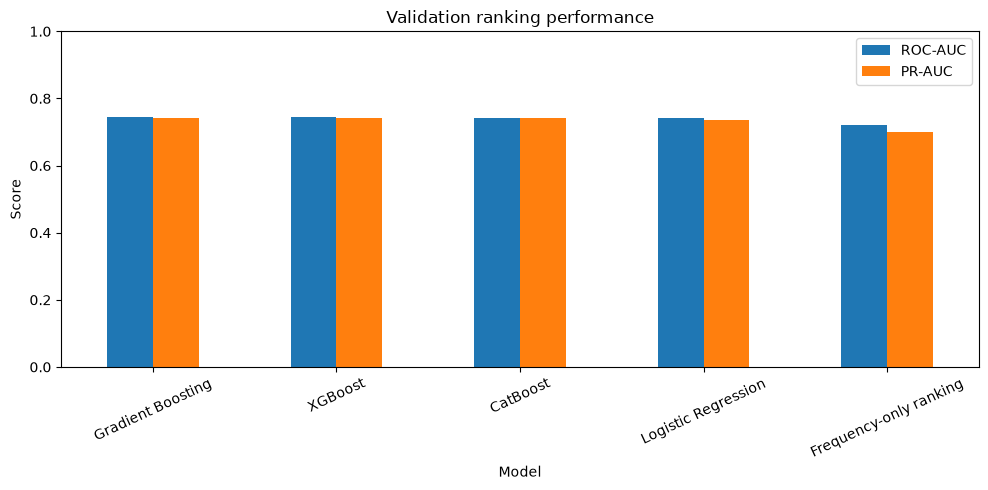

In [15]:
# 7.1 Consolidate validation results

advanced_rows = [
    {"Model": "XGBoost", **xgb_validation_results},
    {"Model": "CatBoost", **catboost_validation_results}
]

validation_comparison = pd.concat([
    baseline_results.reset_index(),
    pd.DataFrame(advanced_rows)
], ignore_index=True)

validation_comparison = validation_comparison.sort_values(
    ["ROC-AUC", "PR-AUC"],
    ascending=False
).reset_index(drop=True)

display(validation_comparison.round(4))

ax = validation_comparison.set_index("Model")[["ROC-AUC", "PR-AUC"]].plot(
    kind="bar", figsize=(10, 5)
)
ax.set_title("Validation ranking performance")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "advanced_model_validation_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()


Highest validation ROC-AUC model: Gradient Boosting
Threshold used for this report: 0.5
              precision    recall  f1-score   support

      Active       0.62      0.68      0.65      4358
    Inactive       0.72      0.66      0.69      5381

    accuracy                           0.67      9739
   macro avg       0.67      0.67      0.67      9739
weighted avg       0.68      0.67      0.67      9739



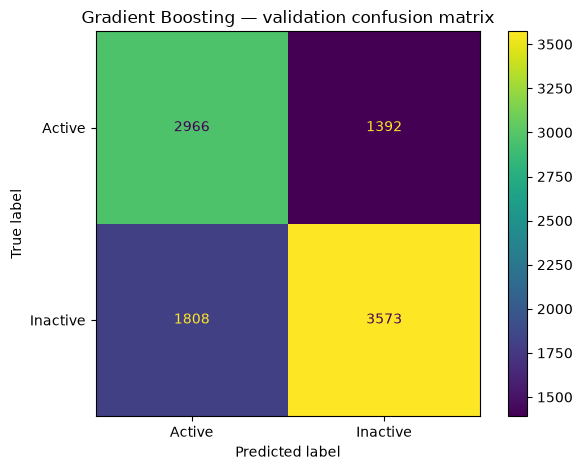

In [16]:
# 7.2 Inspect the best validation-ranked model

# This selects a model from validation results only. It does not evaluate the test set.
probability_by_model = {
    "Logistic Regression": logistic_val_prob,
    "Gradient Boosting": gb_val_prob,
    "XGBoost": xgb_val_prob,
    "CatBoost": catboost_val_prob
}

selected_model_name = validation_comparison.loc[
    validation_comparison["Model"].isin(probability_by_model), "Model"
].iloc[0]
selected_validation_prob = probability_by_model[selected_model_name]

print("Highest validation ROC-AUC model:", selected_model_name)
print("Threshold used for this report:", 0.50)
print(classification_report(
    y_validation,
    (selected_validation_prob >= 0.50).astype(int),
    target_names=["Active", "Inactive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    (selected_validation_prob >= 0.50).astype(int),
    display_labels=["Active", "Inactive"],
    values_format="d"
)
plt.title(f"{selected_model_name} — validation confusion matrix")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "selected_model_validation_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()


## 8. Holdout evaluation (report separately)

The August 2011 snapshot is evaluated only after the validation comparison is complete. However, this snapshot was already examined in Notebook 04, so it is not an untouched test set. Treat the results as a consistency check / previously inspected holdout, not as an unbiased final estimate after repeated experimentation.


Previously inspected holdout — Gradient Boosting


,Holdout metrics
ROC-AUC,0.741848
PR-AUC,0.609306
Accuracy,0.669748
Precision,0.565310
Recall,0.712230
F1,0.630322
Brier score,0.201613


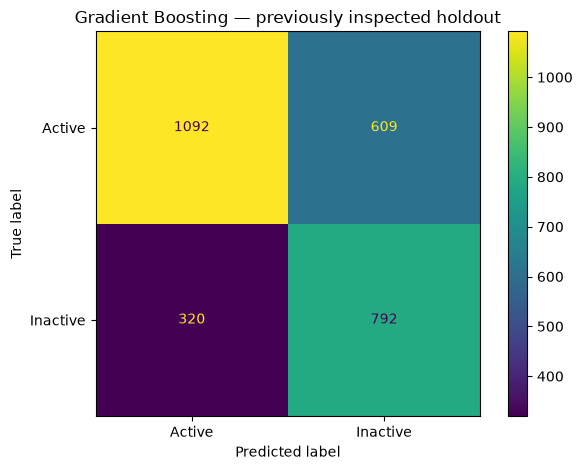

In [17]:
# 8.1 Evaluate the selected validation model on the previously inspected holdout

model_objects = {
    "Logistic Regression": logistic_baseline,
    "Gradient Boosting": gradient_boosting_baseline,
    "XGBoost": xgb_model,
    "CatBoost": catboost_model
}

selected_model = model_objects[selected_model_name]
holdout_prob = selected_model.predict_proba(X_test)[:, 1]
holdout_results = evaluate_probabilities(y_test, holdout_prob)

print("Previously inspected holdout —", selected_model_name)
display(pd.Series(holdout_results, name="Holdout metrics").to_frame())

ConfusionMatrixDisplay.from_predictions(
    y_test,
    (holdout_prob >= 0.50).astype(int),
    display_labels=["Active", "Inactive"],
    values_format="d"
)
plt.title(f"{selected_model_name} — previously inspected holdout")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "selected_model_holdout_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()


## 9. Save reproducible outputs

The notebook saves computed validation and holdout metrics, along with model objects. These are generated from the actual run; no expected metric values are embedded in the code.


In [18]:
# 9.1 Save tables and fitted models

import joblib

validation_output_path = ARTIFACT_DIR / "advanced_model_validation_comparison.csv"
holdout_output_path = ARTIFACT_DIR / "advanced_model_previous_holdout_metrics.csv"
models_output_path = ARTIFACT_DIR / "advanced_inactivity_models.joblib"

validation_comparison.to_csv(validation_output_path, index=False)
pd.DataFrame([{
    "Selected model": selected_model_name,
    **holdout_results
}]).to_csv(holdout_output_path, index=False)

joblib.dump({
    "logistic_regression": logistic_baseline,
    "gradient_boosting": gradient_boosting_baseline,
    "xgboost": xgb_model,
    "catboost": catboost_model,
    "selected_model_name": selected_model_name,
    "feature_columns": FEATURES,
    "target_column": TARGET,
    "observation_months": OBSERVATION_MONTHS,
    "prediction_months": PREDICTION_MONTHS
}, models_output_path)

print("Saved:")
print(validation_output_path)
print(holdout_output_path)
print(models_output_path)


Saved:
c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\artifacts\inactivity\advanced_model_validation_comparison.csv
c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\artifacts\inactivity\advanced_model_previous_holdout_metrics.csv
c:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\artifacts\inactivity\advanced_inactivity_models.joblib


## 10. Research interpretation and limitations

Use the actual tables generated above when writing results. Do not claim that XGBoost or CatBoost is superior unless the computed validation metrics support that conclusion.

Points to state accurately:
1. The task is three-month inactivity classification from a six-month observation history.
2. The comparison uses the same seven numeric customer-level features and the same chronological train/validation split.
3. ROC-AUC and PR-AUC measure ranking performance; threshold-based metrics depend on the selected threshold.
4. Snapshot rows from the same customer can recur across time, so row-level observations are not independent.
5. Inactivity prevalence changes over time; PR-AUC and precision should therefore be interpreted alongside the prevalence of the evaluated period.
6. The August 2011 holdout was previously inspected in earlier work. It must not be described as a pristine untouched test set.
7. This experiment is an algorithm comparison, not proof that the model identifies customers who can be persuaded to return. Inactivity risk and marketing responsiveness are different targets.

**Next rigorous step (not performed here):** use a predeclared expanding-window temporal validation design for model selection, then evaluate once on a genuinely untouched future period if additional data becomes available.
